In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

##Problem 1

In [2]:
data = {
    'Point': ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8'],
    'x': [2, 2, 8, 5, 7, 6, 1, 4],
    'y': [10, 5, 4, 8, 5, 4, 2, 9]
}

df = pd.DataFrame(data)

In [5]:
X = df[['x', 'y']].values
centers = np.array([
    [2, 10],
    [5, 8],
    [1, 2]
], dtype=float)

In [6]:
for iteration in range(10):

    # Calculate Euclidean distance from every point to every centroid
    distances = np.sqrt(
        ((X[:, np.newaxis, :] - centers[np.newaxis, :, :]) ** 2).sum(axis=2)
    )

    # Assign each point to nearest centroid
    clusters = np.argmin(distances, axis=1)

    # Store old centers
    old_centers = centers.copy()

    # Recalculate centroids
    for k in range(3):
        points = X[clusters == k]

        if len(points) > 0:
            centers[k] = points.mean(axis=0)

    # Display iteration
    print(f"\nIteration {iteration + 1}")

    result = df.copy()
    result['Cluster'] = clusters + 1

    print(result[['Point', 'x', 'y', 'Cluster']])

    print("\nCenters:")
    print(centers)

    # Stop if centroids no longer change
    if np.allclose(centers, old_centers):
        print("\nConverged.")
        break


Iteration 1
  Point  x   y  Cluster
0    A1  2  10        1
1    A2  2   5        3
2    A3  8   4        2
3    A4  5   8        2
4    A5  7   5        2
5    A6  6   4        2
6    A7  1   2        3
7    A8  4   9        2

Centers:
[[ 2.  10. ]
 [ 6.   6. ]
 [ 1.5  3.5]]

Iteration 2
  Point  x   y  Cluster
0    A1  2  10        1
1    A2  2   5        3
2    A3  8   4        2
3    A4  5   8        2
4    A5  7   5        2
5    A6  6   4        2
6    A7  1   2        3
7    A8  4   9        1

Centers:
[[3.   9.5 ]
 [6.5  5.25]
 [1.5  3.5 ]]

Iteration 3
  Point  x   y  Cluster
0    A1  2  10        1
1    A2  2   5        3
2    A3  8   4        2
3    A4  5   8        1
4    A5  7   5        2
5    A6  6   4        2
6    A7  1   2        3
7    A8  4   9        1

Centers:
[[3.66666667 9.        ]
 [7.         4.33333333]
 [1.5        3.5       ]]

Iteration 4
  Point  x   y  Cluster
0    A1  2  10        1
1    A2  2   5        3
2    A3  8   4        2
3    A4  5   8    

In [7]:
result = df.copy()
result['Cluster'] = clusters + 1

print("\nFinal Clustering:")
print(result[['Point', 'x', 'y', 'Cluster']])

print("\nFinal Centroids:")
print(centers)


Final Clustering:
  Point  x   y  Cluster
0    A1  2  10        1
1    A2  2   5        3
2    A3  8   4        2
3    A4  5   8        1
4    A5  7   5        2
5    A6  6   4        2
6    A7  1   2        3
7    A8  4   9        1

Final Centroids:
[[3.66666667 9.        ]
 [7.         4.33333333]
 [1.5        3.5       ]]


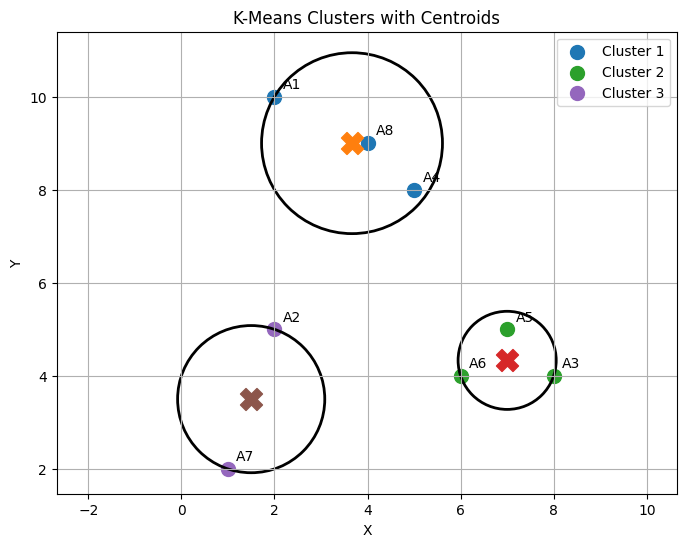

In [10]:
plt.figure(figsize=(8, 6))

for k in range(3):

    # Points belonging to this cluster
    points = X[clusters == k]

    # Plot points
    plt.scatter(
        points[:, 0],
        points[:, 1],
        s=100,
        label=f'Cluster {k + 1}'
    )

    # Centroid
    centroid = centers[k]

    plt.scatter(
        centroid[0],
        centroid[1],
        marker='X',
        s=250
    )

    distances = np.sqrt(
        ((points - centroid) ** 2).sum(axis=1)
    )

    radius = distances.max()

    # Draw circle around cluster
    circle = plt.Circle(
        centroid,
        radius,
        fill=False,
        linewidth=2
    )

    plt.gca().add_patch(circle)


for i, point in enumerate(df['Point']):
    plt.annotate(
        point,
        (X[i, 0], X[i, 1]),
        xytext=(6, 6),
        textcoords='offset points'
    )

plt.xlabel('X')
plt.ylabel('Y')
plt.title('K-Means Clusters with Centroids')
plt.legend()
plt.grid(True)

plt.axis('equal')

plt.show()

##Problem 2

In [11]:
data = {
    'Customer': ['John', 'Rachel', 'Hannah', 'Tom', 'Nellie'],
    'Age': [35, 22, 63, 59, 25],
    'Income': [35, 50, 200, 170, 40],
    'No. credit cards': [3, 2, 1, 1, 4],
    'Response': ['No', 'Yes', 'No', 'No', 'Yes']
}

df = pd.DataFrame(data)

In [12]:
df

,Customer,Age,Income,No. credit cards,Response
0,John,35,35,3,No
1,Rachel,22,50,2,Yes
2,Hannah,63,200,1,No
3,Tom,59,170,1,No
4,Nellie,25,40,4,Yes


In [13]:
X = df[['Age', 'Income', 'No. credit cards']].values.astype(float)
y = df['Response'].values


In [14]:
david = np.array([37, 50, 2], dtype=float)

In [15]:
distances = np.sqrt(
    ((X - david) ** 2).sum(axis=1)
)

In [16]:
df['Distance'] = distances
df = df.sort_values('Distance')


In [17]:
k = 3
neighbors = df.iloc[:k]

print("3 Nearest Neighbors:")
print(neighbors[['Customer', 'Age', 'Income',
                  'No. credit cards', 'Response', 'Distance']])

3 Nearest Neighbors:
  Customer  Age  Income  No. credit cards Response   Distance
1   Rachel   22      50                 2      Yes  15.000000
0     John   35      35                 3       No  15.165751
4   Nellie   25      40                 4      Yes  15.748016


In [18]:
response_counts = neighbors['Response'].value_counts()

In [19]:
prediction = response_counts.idxmax()

In [20]:
print("\nPredicted Response for David:", prediction)


Predicted Response for David: Yes
